# 07 — Comparative Evaluation of Object Detection Models

## Aim

Compare YOLOv8n, RetinaNet ResNet50-FPN V2 and Faster R-CNN ResNet50-FPN V2 for detecting four pork rasher packaging defects.

## Objectives

1. Load the best saved checkpoint from each model.
2. Evaluate all three detectors on identical validation and test datasets.
3. Compare overall and per-class COCO-style average precision.
4. Select confidence thresholds using validation data only.
5. Compare confusion matrices, Micro-F1, Macro-F1 and detection errors.
6. Evaluate inference latency, throughput, model size and GPU memory.
7. Analyse differences between validation and held-out test performance.

The notebook reuses the documented `mma3001` Python package. All checkpoints and experiment records are loaded from Google Drive. No dataset generation, training or parameter optimisation is performed.

In [1]:

# Install packages required for saved-checkpoint evaluation.
%pip install -q ultralytics torchmetrics pycocotools pandas matplotlib pillow pyyaml


In [2]:

# Mount Google Drive and load shared evaluation code from GitHub.

import gc
import os
import subprocess
import sys
import time

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from PIL import Image
from IPython.display import display
from google.colab import drive
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.ops import box_iou
from torchvision.transforms import functional as TF

REPO_URL = "https://github.com/daniellawjmcc/MMA3001_Project.git"
REPO_ROOT = Path("/content/MMA3001_Project_repo")

DRIVE_ROOT = Path("/content/gdrive_new")
DEFAULT_PROJECT_ROOT = DRIVE_ROOT / "MyDrive" / "MMA3001_Project"

if not DEFAULT_PROJECT_ROOT.is_dir():
    drive.mount(str(DRIVE_ROOT))

if not REPO_ROOT.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )

source_path = str(REPO_ROOT / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)

from mma3001.config import (
    FOUR_CLASS_NAMES,
    SEED,
    find_project_root,
    get_dataset_path,
    get_run_path,
    get_checkpoint_path,
    set_seed,
)
from mma3001.dataset import (
    YoloDetectionDataset,
    load_class_names,
)
from mma3001.evaluation import (
    evaluate_threshold,
    evaluate_thresholds,
    select_best_threshold,
    per_class_recall_table,
)
from mma3001.metrics import summarise_confusion_matrix
from mma3001.plotting import (
    plot_confusion_matrix,
    plot_threshold_metrics,
)
from mma3001.models import (
    load_experiment_model,
    count_parameters,
)

set_seed(SEED)

PROJECT_ROOT = find_project_root(
    os.environ.get(
        "MMA3001_PROJECT_ROOT",
        str(DEFAULT_PROJECT_ROOT),
    )
)

DATASET_ROOT = get_dataset_path(PROJECT_ROOT, four_class=True)

OUTPUT_DIR = PROJECT_ROOT / "comparison_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_DIR = OUTPUT_DIR / "report_figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ["YOLOv8n", "RetinaNet", "Faster R-CNN"]

RUN_KEYS = {
    "YOLOv8n": "yolo_4class",
    "RetinaNet": "retinanet_4class",
    "Faster R-CNN": "faster_rcnn_4class",
}

CLASS_NAMES = list(FOUR_CLASS_NAMES)
NUM_CLASSES = len(CLASS_NAMES)
MATRIX_LABELS = CLASS_NAMES + ["background"]

IMAGE_SIZE = 640
MATCH_IOU = 0.50

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025),
    3,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_paths = {
    name: get_checkpoint_path(PROJECT_ROOT, run_name)
    for name, run_name in RUN_KEYS.items()
}

dataset_mapping = load_class_names(DATASET_ROOT)

assert [
    dataset_mapping[index]
    for index in range(NUM_CLASSES)
] == CLASS_NAMES

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)
print("Device:", device)
print("Classes:", CLASS_NAMES)

for name, path in checkpoint_paths.items():
    print(name, "checkpoint:", path)


Mounted at /content/gdrive_new
Project: /content/gdrive_new/MyDrive/MMA3001_Project
Dataset: /content/gdrive_new/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
Device: cpu
Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed']
YOLOv8n checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/yolov8n_4class_30epochs/weights/best.pt
RetinaNet checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/retinanet_resnet50_4class/best.pt
Faster R-CNN checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/faster_rcnn_resnet50_4class/best.pt


## 1. Standardised Dataset Verification

The three detectors are evaluated using the same four-class validation and test images.

The shared dataset loader converts YOLO-format annotations into pixel-coordinate bounding boxes. For the common evaluation, all class labels use zero-based IDs from 0 to 3.

Validation data is used for model comparison and threshold selection. The test dataset is evaluated after these decisions have been fixed.

In [3]:

# Load validation and held-out test annotations in common class-ID format.

valid_dataset = YoloDetectionDataset(
    DATASET_ROOT,
    split="valid",
    label_offset=0,
)

test_dataset = YoloDetectionDataset(
    DATASET_ROOT,
    split="test",
    label_offset=0,
)


def collect_targets(dataset):
    """Collect image paths and ground-truth targets from a dataset.

    Args:
        dataset: Object detection dataset containing images and
            their corresponding ground-truth annotations.

    Returns:
        Tuple containing a list of image paths and a list of
        ground-truth dictionaries. Each dictionary contains
        bounding boxes and zero-based class labels in dataset order.
    """
    images = list(dataset.image_paths)
    targets = []

    for index in range(len(dataset)):
        _, target = dataset[index]

        targets.append({
            "boxes": target["boxes"],
            "labels": target["labels"],
        })

    return images, targets


valid_image_paths, valid_targets = collect_targets(valid_dataset)
test_image_paths, test_targets = collect_targets(test_dataset)

assert len(valid_image_paths) == 120
assert len(test_image_paths) == 80


def count_annotations(targets):
    """Count ground-truth annotations for each defect class.

    Args:
        targets: List of ground-truth dictionaries containing
            bounding boxes and zero-based class labels.

    Returns:
        NumPy array containing the total annotation count for
        each of the four defect classes.
    """

    counts = np.zeros(NUM_CLASSES, dtype=int)

    for target in targets:
        for label in target["labels"]:
            counts[int(label)] += 1

    return counts


dataset_summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Validation": count_annotations(valid_targets),
    "Test": count_annotations(test_targets),
})

print("DATASET SUMMARY")
print("Validation images:", len(valid_image_paths))
print("Test images:", len(test_image_paths))

display(dataset_summary)


DATASET SUMMARY
Validation images: 120
Test images: 80


,Class,Validation,Test
0,loose-meat,3,3
1,packaging-error,34,23
2,twisted-meat,3,4
3,unsealed,81,49


## 2. Historical Training and Checkpoint Selection

The three final models were trained separately, and their best checkpoints were selected using validation performance.

The saved training-history files allow their validation mAP@50:95 trajectories to be compared without retraining.

The figure presents each model's recorded validation performance against training epoch, highlighting the selected checkpoint. This historical training comparison is separate from the common-evaluator comparison performed earlier in this notebook.

CHECKPOINT SELECTION SUMMARY


,Model,Total_Epochs,Selected_Epoch,Checkpoint_Validation_mAP5095
0,YOLOv8n,30,30,0.3057
1,RetinaNet,15,13,0.2465
2,Faster R-CNN,15,3,0.3222


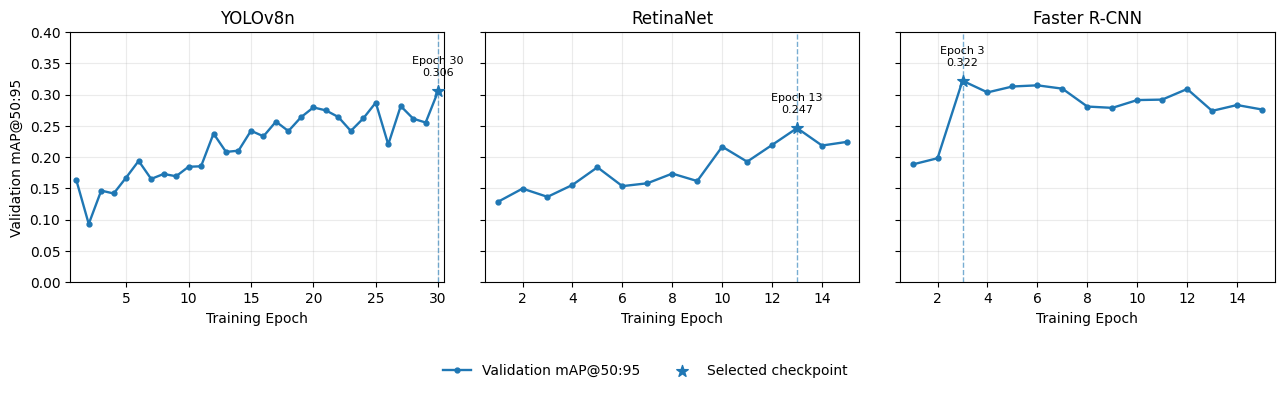

In [4]:

# Compare validation mAP history using saved training logs only.

histories = {}
selection_rows = []

for name in MODEL_NAMES:
    run_name = RUN_KEYS[name]
    run_dir = get_run_path(PROJECT_ROOT, run_name)

    if name == "YOLOv8n":
        history_path = run_dir / "results.csv"
        epoch_column = "epoch"
        map_column = "metrics/mAP50-95(B)"
    else:
        history_path = run_dir / "training_history.csv"
        epoch_column = "Epoch"
        map_column = "Val_mAP50_95"

    if not history_path.is_file():
        raise FileNotFoundError(
            f"Missing original training history: {history_path}"
        )

    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()

    epochs = pd.to_numeric(history[epoch_column])
    map_values = pd.to_numeric(history[map_column])

    # Normalise zero-based logs to display epochs starting from one.
    if epochs.min() == 0:
        epochs = epochs + 1

    standard_history = pd.DataFrame({
        "epoch": epochs.astype(int),
        "map5095": map_values.astype(float),
    }).dropna()

    if name == "YOLOv8n":
        selected_epoch = int(
            standard_history.loc[
                standard_history["map5095"].idxmax(),
                "epoch",
            ]
        )
    else:
        checkpoint_metadata = torch.load(
            checkpoint_paths[name],
            map_location="cpu",
            weights_only=True,
        )
        selected_epoch = int(checkpoint_metadata["epoch"])
        del checkpoint_metadata

    selected_row = standard_history[
        standard_history["epoch"] == selected_epoch
    ]

    if selected_row.empty:
        raise ValueError(
            f"{name}: checkpoint epoch missing from saved history."
        )

    selected_map = float(selected_row["map5095"].iloc[0])

    histories[name] = {
        "history": standard_history,
        "epoch": selected_epoch,
        "map": selected_map,
    }

    selection_rows.append({
        "Model": name,
        "Total_Epochs": int(standard_history["epoch"].max()),
        "Selected_Epoch": selected_epoch,
        "Checkpoint_Validation_mAP5095": selected_map,
    })

selection_df = pd.DataFrame(selection_rows)

print("CHECKPOINT SELECTION SUMMARY")
display(selection_df.round(4))

fig, axes = plt.subplots(
    1, 3, figsize=(13, 3.8), sharey=True
)

for ax, name in zip(axes, MODEL_NAMES):
    data = histories[name]
    history = data["history"]

    ax.plot(
        history["epoch"],
        history["map5095"],
        marker="o",
        markersize=3.5,
        linewidth=1.7,
        label="Validation mAP@50:95",
    )

    ax.scatter(
        data["epoch"],
        data["map"],
        s=75,
        marker="*",
        zorder=5,
        label="Selected checkpoint",
    )

    ax.axvline(
        data["epoch"],
        linestyle="--",
        linewidth=1,
        alpha=0.6,
    )

    ax.annotate(
        f"Epoch {data['epoch']}\n{data['map']:.3f}",
        xy=(data["epoch"], data["map"]),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

    ax.set_title(name)
    ax.set_xlabel("Training Epoch")
    ax.set_xlim(
        0.5,
        max(2, history["epoch"].max() + 0.5),
    )
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Validation mAP@50:95")

all_scores = np.concatenate([
    histories[name]["history"]["map5095"].to_numpy()
    for name in MODEL_NAMES
])

axes[0].set_ylim(
    0,
    max(0.4, float(all_scores.max()) * 1.15),
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(
    REPORT_DIR / "figure_4_3_1_validation_history.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    REPORT_DIR / "figure_4_3_1_validation_history.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

selection_df.to_csv(
    OUTPUT_DIR / "checkpoint_selection.csv",
    index=False,
)


## 3. Saved Model Checkpoints

YOLOv8n, RetinaNet and Faster R-CNN are loaded from their original best validation checkpoints.

All models use their original inference preprocessing and postprocessing configurations. RetinaNet and Faster R-CNN use Torchvision-compatible one-based defect labels internally; outputs are converted to zero-based labels for the shared evaluation.

Strict checkpoint loading verifies that saved parameter names and dimensions match the reconstructed architectures.

In [5]:

# Load the three final saved models without retraining.

yolo_model = load_experiment_model(
    PROJECT_ROOT, "yolo_4class"
)

retinanet_model = load_experiment_model(
    PROJECT_ROOT, "retinanet_4class", device=device
)

faster_model = load_experiment_model(
    PROJECT_ROOT, "faster_rcnn_4class", device=device
)

# Restore the original 640-pixel resizing and RetinaNet settings.
retinanet_model.transform.min_size = (640,)
retinanet_model.transform.max_size = 640
retinanet_model.score_thresh = 0.05
retinanet_model.nms_thresh = 0.50
retinanet_model.detections_per_img = 100

# Restore the original Faster R-CNN inference settings.
faster_model.transform.min_size = (640,)
faster_model.transform.max_size = 640
faster_model.roi_heads.score_thresh = 0.001
faster_model.roi_heads.nms_thresh = 0.50
faster_model.roi_heads.detections_per_img = 100

retinanet_model.eval()
faster_model.eval()

model_objects = {
    "YOLOv8n": yolo_model,
    "RetinaNet": retinanet_model,
    "Faster R-CNN": faster_model,
}

print("All three final checkpoints loaded successfully.")
print("YOLO classes:", yolo_model.names)
print("RetinaNet output classes:",
      retinanet_model.head.classification_head.num_classes)
print("Faster R-CNN output classes:",
      faster_model.roi_heads.box_predictor.cls_score.out_features)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
All three final checkpoints loaded successfully.
YOLO classes: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'}
RetinaNet output classes: 5
Faster R-CNN output classes: 5


In [6]:

# Convert all model outputs to boxes, scores and zero-based labels.


def load_image_tensor(image_path):
    """Load an RGB image as a normalised PyTorch tensor.

    Args:
        image_path: Path to the image file to load.

    Returns:
        PyTorch tensor with shape (3, H, W), containing RGB
        pixel values normalised to the range [0, 1].

    Raises:
        FileNotFoundError: If the specified image file does not exist.
        OSError: If the image cannot be opened or decoded.
    """

    # Load an RGB image with values between zero and one.
    with Image.open(image_path) as image:
        return TF.to_tensor(image.convert("RGB"))



@torch.inference_mode()
def predict_yolo(image_paths):
    """Generate YOLOv8n detections for a collection of images.

    The saved YOLOv8n model performs inference using 640-pixel
    images, a minimum confidence of 0.001 and NMS IoU of 0.70.

    Args:
        image_paths: Ordered list of image paths used for inference.

    Returns:
        List of detection dictionaries, one per image. Each
        dictionary contains predicted bounding boxes, confidence
        scores and zero-based class labels stored on the CPU.
    """

    predictions = []

    stream = yolo_model.predict(
        source=[str(path) for path in image_paths],
        imgsz=IMAGE_SIZE,
        conf=0.001,
        iou=0.70,
        max_det=300,
        device=0 if device.type == "cuda" else "cpu",
        stream=True,
        verbose=False,
    )

    for result in stream:
        boxes = result.boxes

        predictions.append({
            "boxes": boxes.xyxy.detach().cpu(),
            "scores": boxes.conf.detach().cpu(),
            "labels": boxes.cls.detach().cpu().long(),
        })

    return predictions



@torch.inference_mode()
def predict_torchvision(model, image_paths):
    """Generate Torchvision object detection predictions.

    The function performs inference using a loaded RetinaNet or
    Faster R-CNN model. Predicted class labels are converted from
    one-based Torchvision IDs to zero-based evaluation IDs.

    Reserved or invalid class labels are excluded from the results.

    Args:
        model: Loaded RetinaNet or Faster R-CNN detection model.
        image_paths: Ordered list of image paths used for inference.

    Returns:
        List of detection dictionaries, one per image. Each
        dictionary contains bounding boxes, confidence scores
        and zero-based class labels stored on the CPU.
    """

    model.eval()
    predictions = []

    for image_path in image_paths:
        image = load_image_tensor(image_path).to(device)
        result = model([image])[0]

        labels = result["labels"].detach().cpu().long() - 1
        boxes = result["boxes"].detach().cpu()
        scores = result["scores"].detach().cpu()

        # Remove reserved label-zero outputs, if any.
        keep = (labels >= 0) & (labels < NUM_CLASSES)

        predictions.append({
            "boxes": boxes[keep],
            "scores": scores[keep],
            "labels": labels[keep],
        })

    return predictions



def collect_model_predictions(image_paths):
    """Collect predictions from all three trained object detectors.

    YOLOv8n, RetinaNet and Faster R-CNN are evaluated using the
    same ordered image list and their original inference settings.

    Args:
        image_paths: Ordered list of image paths shared by all models.

    Returns:
        Dictionary mapping model names to lists of detection
        predictions. The keys are YOLOv8n, RetinaNet and Faster R-CNN.
    """

    return {
        "YOLOv8n": predict_yolo(image_paths),
        "RetinaNet": predict_torchvision(
            retinanet_model, image_paths
        ),
        "Faster R-CNN": predict_torchvision(
            faster_model, image_paths
        ),
    }



def evaluate_map(predictions, targets):
    """Calculate COCO-style object detection average precision.

    The function uses TorchMetrics to evaluate confidence-ranked
    predictions against ground-truth annotations using consistent
    bounding-box and class-label conventions.

    Args:
        predictions: List of detection dictionaries containing
            predicted boxes, confidence scores and class labels.
        targets: List of ground-truth dictionaries containing
            bounding boxes and class labels.

    Returns:
        Dictionary of COCO-style detection metrics, including
        mAP@50, mAP@50:95, mAP@75, mean average recall and
        per-class average precision.
    """

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=True,
    )

    metric.update(predictions, targets)
    return metric.compute()



def verify_predictions(predictions, targets):
    """Verify the structural validity of model detection predictions.

    The function checks prediction counts, bounding-box dimensions,
    confidence-score lengths, class-label ranges and finite values
    before the predictions are used for comparative evaluation.

    Args:
        predictions: List of model prediction dictionaries.
        targets: List of ground-truth dictionaries corresponding
            to the same ordered images.

    Returns:
        None. The function completes without output when all
        prediction records satisfy the required checks.

    Raises:
        AssertionError: If prediction counts, tensor dimensions,
            confidence scores or class labels are invalid.
    """

    assert len(predictions) == len(targets)

    for record in predictions:
        assert record["boxes"].ndim == 2
        assert record["boxes"].shape[1] == 4
        assert len(record["boxes"]) == len(record["scores"])
        assert len(record["scores"]) == len(record["labels"])

        assert torch.isfinite(record["boxes"]).all()
        assert torch.isfinite(record["scores"]).all()

        if len(record["labels"]):
            assert int(record["labels"].min()) >= 0
            assert int(record["labels"].max()) < NUM_CLASSES


In [7]:

# Generate all validation predictions once for every subsequent analysis.

validation_predictions = collect_model_predictions(valid_image_paths)

for name in MODEL_NAMES:
    verify_predictions(
        validation_predictions[name],
        valid_targets,
    )

    prediction_count = sum(
        len(record["scores"])
        for record in validation_predictions[name]
    )

    print(f"{name}: {prediction_count} validation predictions")

print("\nAll validation predictions verified.")


YOLOv8n: 1368 validation predictions
RetinaNet: 1442 validation predictions
Faster R-CNN: 1427 validation predictions

All validation predictions verified.


## 4. Standardised Validation Performance

All three detectors are evaluated using the same COCO-style metric implementation.

The comparison reports mAP@50, mAP@50:95 and per-class AP@50:95. Identical validation images and ground-truth annotations are used for all three models.

mAP is computed from confidence-ranked detections and must not be approximated using a single confidence-threshold confusion matrix.

Evaluating validation mAP: YOLOv8n
Evaluating validation mAP: RetinaNet
Evaluating validation mAP: Faster R-CNN
STANDARDISED VALIDATION mAP


,Model,mAP50,mAP50_95
0,YOLOv8n,0.5147,0.3278
1,RetinaNet,0.4098,0.2465
2,Faster R-CNN,0.5662,0.3222



PER-CLASS AP@50:95


Model,Faster R-CNN,RetinaNet,YOLOv8n
Class,,,
loose-meat,0.4663,0.1727,0.2020
packaging-error,0.0458,0.0545,0.1223
twisted-meat,0.2020,0.2020,0.3432
unsealed,0.5748,0.5569,0.6437


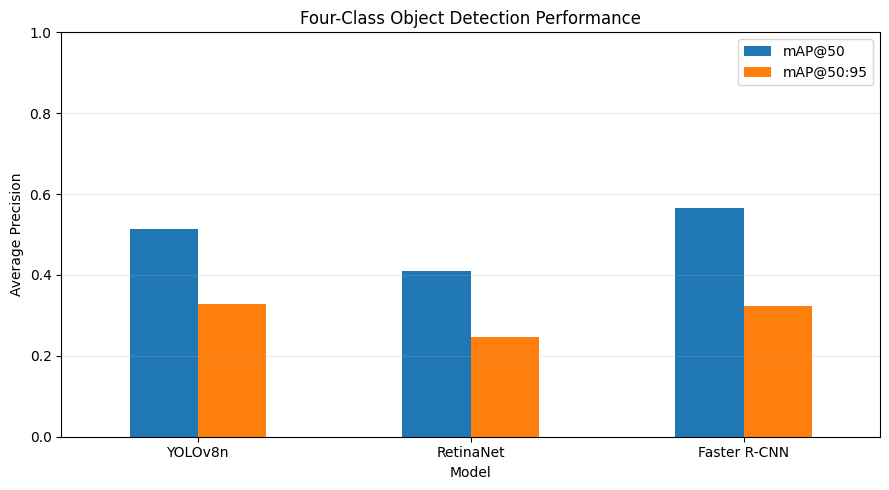

In [8]:

# Compare overall and per-class average precision on validation data.

overall_rows = []
per_class_rows = []

for name in MODEL_NAMES:
    print("Evaluating validation mAP:", name)

    result = evaluate_map(
        validation_predictions[name],
        valid_targets,
    )

    overall_rows.append({
        "Model": name,
        "mAP50": float(result["map_50"]),
        "mAP50_95": float(result["map"]),
    })

    class_ap = {
        int(class_id): float(ap)
        for class_id, ap in zip(
            result["classes"],
            result["map_per_class"],
        )
    }

    for class_id, class_name in enumerate(CLASS_NAMES):
        per_class_rows.append({
            "Model": name,
            "Class": class_name,
            "AP50_95": class_ap.get(class_id, np.nan),
        })

overall_map_df = pd.DataFrame(overall_rows)
per_class_ap_df = pd.DataFrame(per_class_rows)

print("STANDARDISED VALIDATION mAP")
display(overall_map_df.round(4))

print("\nPER-CLASS AP@50:95")
display(
    per_class_ap_df.pivot(
        index="Class",
        columns="Model",
        values="AP50_95",
    ).round(4)
)

overall_map_df.to_csv(
    OUTPUT_DIR / "validation_overall_map.csv",
    index=False,
)

per_class_ap_df.to_csv(
    OUTPUT_DIR / "validation_per_class_ap.csv",
    index=False,
)

# Preserve the original model-ranking figure.
ax = overall_map_df.set_index("Model")[
    ["mAP50", "mAP50_95"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Four-Class Object Detection Performance")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(["mAP@50", "mAP@50:95"])
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "validation_map_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


## 5. Validation Confidence-Threshold Selection

A fine confidence sweep from 0.10 to 0.50, with increments of 0.025, is applied to each model using the same IoU matching threshold of 0.50.

Micro-F1 measures overall detection performance, while Macro-F1 gives equal weight to the four defect categories.

For the held-out test evaluation, each model's Macro-F1 confidence threshold is selected using validation data and then frozen. Test outcomes are not used to modify model selection or confidence thresholds.

In [9]:

# Use the shared IoU evaluator to select validation operating points.

threshold_frames = []
class_frames = []
selected_rows = []

for name in MODEL_NAMES:
    overall, classes, _ = evaluate_thresholds(
        predictions=validation_predictions[name],
        targets=valid_targets,
        thresholds=FINE_THRESHOLDS,
        class_names=CLASS_NAMES,
        iou_threshold=MATCH_IOU,
        label_offset=0,
    )

    overall["Model"] = name
    classes["Model"] = name

    threshold_frames.append(overall)
    class_frames.append(classes)

    best_micro = select_best_threshold(
        overall, metric="F1"
    )
    best_macro = select_best_threshold(
        overall, metric="Macro-F1"
    )

    selected_rows.append({
        "Model": name,
        "Micro_Threshold": float(best_micro["Threshold"]),
        "Best_Micro_F1": float(best_micro["F1"]),
        "Macro_Threshold": float(best_macro["Threshold"]),
        "Best_Macro_F1": float(best_macro["Macro-F1"]),
        "Macro_Point_Precision": float(best_macro["Precision"]),
        "Macro_Point_Recall": float(best_macro["Recall"]),
        "Macro_Point_Micro_F1": float(best_macro["F1"]),
    })

threshold_df = pd.concat(
    threshold_frames, ignore_index=True
)

class_threshold_df = pd.concat(
    class_frames, ignore_index=True
)

selected_df = pd.DataFrame(selected_rows)

# Preserve original column names used by the comparison tables.
threshold_df = threshold_df.rename(columns={
    "F1": "Micro_F1",
    "Macro-F1": "Macro_F1",
})

print("CONFIDENCE THRESHOLD SENSITIVITY")
display(threshold_df[
    [
        "Model",
        "Threshold",
        "Precision",
        "Recall",
        "Micro_F1",
        "Macro_F1",
    ]
].round(4))

print("\nVALIDATION-SELECTED OPERATING POINTS")
display(selected_df.round(4))

threshold_df.to_csv(
    OUTPUT_DIR / "validation_threshold_sweep.csv",
    index=False,
)

selected_df.to_csv(
    OUTPUT_DIR / "selected_thresholds.csv",
    index=False,
)

# Preserve selected thresholds as independent frozen values.
frozen_thresholds = {
    row["Model"]: float(row["Macro_Threshold"])
    for _, row in selected_df.iterrows()
}

print("\nFROZEN TEST OPERATING POINTS")
print(frozen_thresholds)


CONFIDENCE THRESHOLD SENSITIVITY


,Model,Threshold,Precision,Recall,Micro_F1,Macro_F1
0,YOLOv8n,0.100,0.5266,0.8182,0.6408,0.5354
1,YOLOv8n,0.125,0.5491,0.7851,0.6463,0.5455
2,YOLOv8n,0.150,0.6090,0.7851,0.6859,0.6015
3,YOLOv8n,0.175,0.6463,0.7851,0.7090,0.6116
4,YOLOv8n,0.200,0.6667,0.7769,0.7176,0.6161
5,YOLOv8n,0.225,0.6947,0.7521,0.7222,0.4291
6,YOLOv8n,0.250,0.7479,0.7355,0.7417,0.4332
7,YOLOv8n,0.275,0.7611,0.7107,0.7350,0.4196
8,YOLOv8n,0.300,0.7818,0.7107,0.7446,0.4243
9,YOLOv8n,0.325,0.8095,0.7025,0.7522,0.4239



VALIDATION-SELECTED OPERATING POINTS


,Model,Micro_Threshold,Best_Micro_F1,Macro_Threshold,Best_Macro_F1,Macro_Point_Precision,Macro_Point_Recall,Macro_Point_Micro_F1
0,YOLOv8n,0.45,0.7664,0.2,0.6161,0.6667,0.7769,0.7176
1,RetinaNet,0.50,0.6979,0.2,0.3142,0.4314,0.7273,0.5415
2,Faster R-CNN,0.50,0.6809,0.5,0.5962,0.7018,0.6612,0.6809



FROZEN TEST OPERATING POINTS
{'YOLOv8n': 0.2, 'RetinaNet': 0.2, 'Faster R-CNN': 0.5}


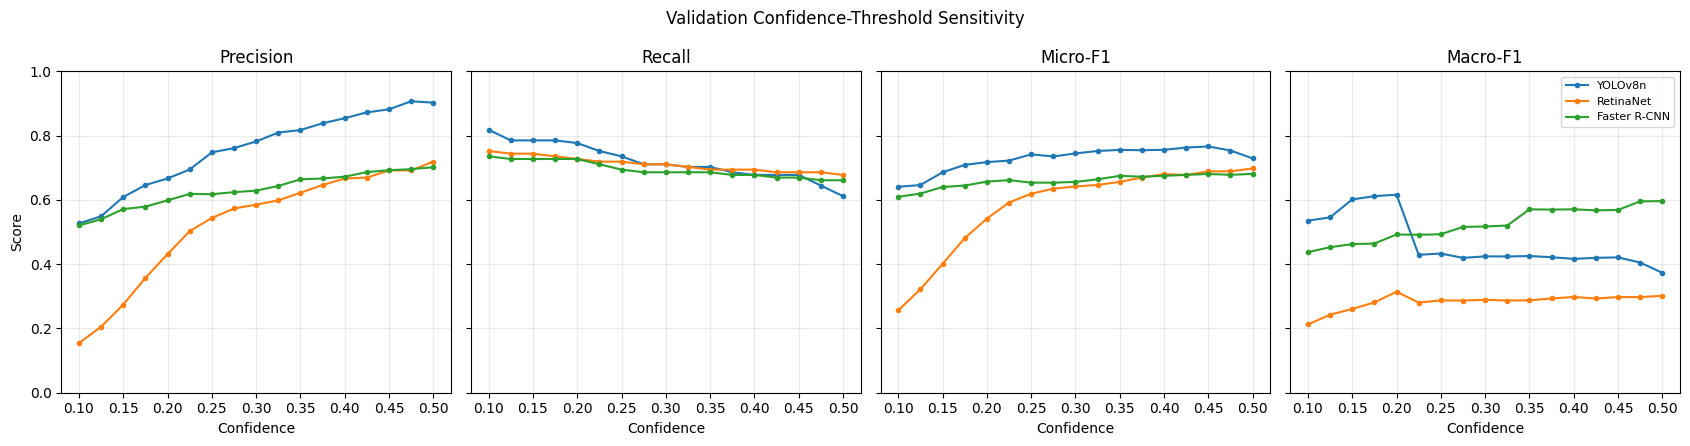

In [10]:

# Plot precision, recall, Micro-F1 and Macro-F1 for all three models.

metrics_to_plot = [
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("Micro_F1", "Micro-F1"),
    ("Macro_F1", "Macro-F1"),
]

fig, axes = plt.subplots(
    1, 4, figsize=(17, 4.5), sharex=True, sharey=True
)

for ax, (column, title) in zip(axes, metrics_to_plot):
    for name in MODEL_NAMES:
        rows = threshold_df[
            threshold_df["Model"] == name
        ].sort_values("Threshold")

        ax.plot(
            rows["Threshold"],
            rows[column],
            marker="o",
            markersize=3,
            label=name,
        )

    ax.set_title(title)
    ax.set_xlabel("Confidence")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Score")
axes[-1].legend(fontsize=8)

fig.suptitle("Validation Confidence-Threshold Sensitivity")
fig.tight_layout()

fig.savefig(
    REPORT_DIR / "threshold_sensitivity_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


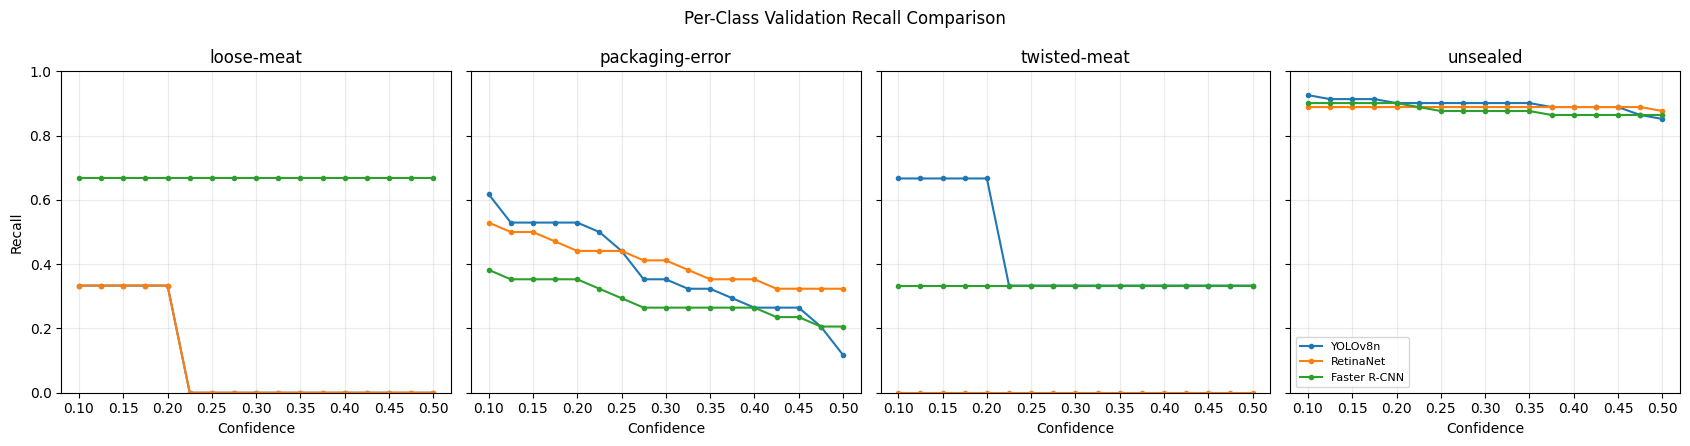

In [11]:

# Compare recall trends across models for all four defect categories.

fig, axes = plt.subplots(
    1, NUM_CLASSES, figsize=(17, 4.5), sharey=True
)

for ax, class_name in zip(axes, CLASS_NAMES):
    for name in MODEL_NAMES:
        rows = class_threshold_df[
            (class_threshold_df["Model"] == name)
            & (class_threshold_df["Class"] == class_name)
        ].sort_values("Threshold")

        ax.plot(
            rows["Threshold"],
            rows["Recall"],
            marker="o",
            markersize=3,
            label=name,
        )

    ax.set_title(class_name)
    ax.set_xlabel("Confidence")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Recall")
axes[-1].legend(fontsize=8)

fig.suptitle("Per-Class Validation Recall Comparison")
fig.tight_layout()

fig.savefig(
    REPORT_DIR / "per_class_recall_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


## 6. Confusion Matrix and Detection Error Comparison

Each model is evaluated at its validation-selected Macro-F1 confidence threshold.

Raw and normalised confusion matrices are compared using identical class ordering and IoU matching rules.

Detection errors are separated into missed ground-truth objects, unmatched predictions and incorrect-class matches. This comparison provides information that overall mAP alone cannot show.

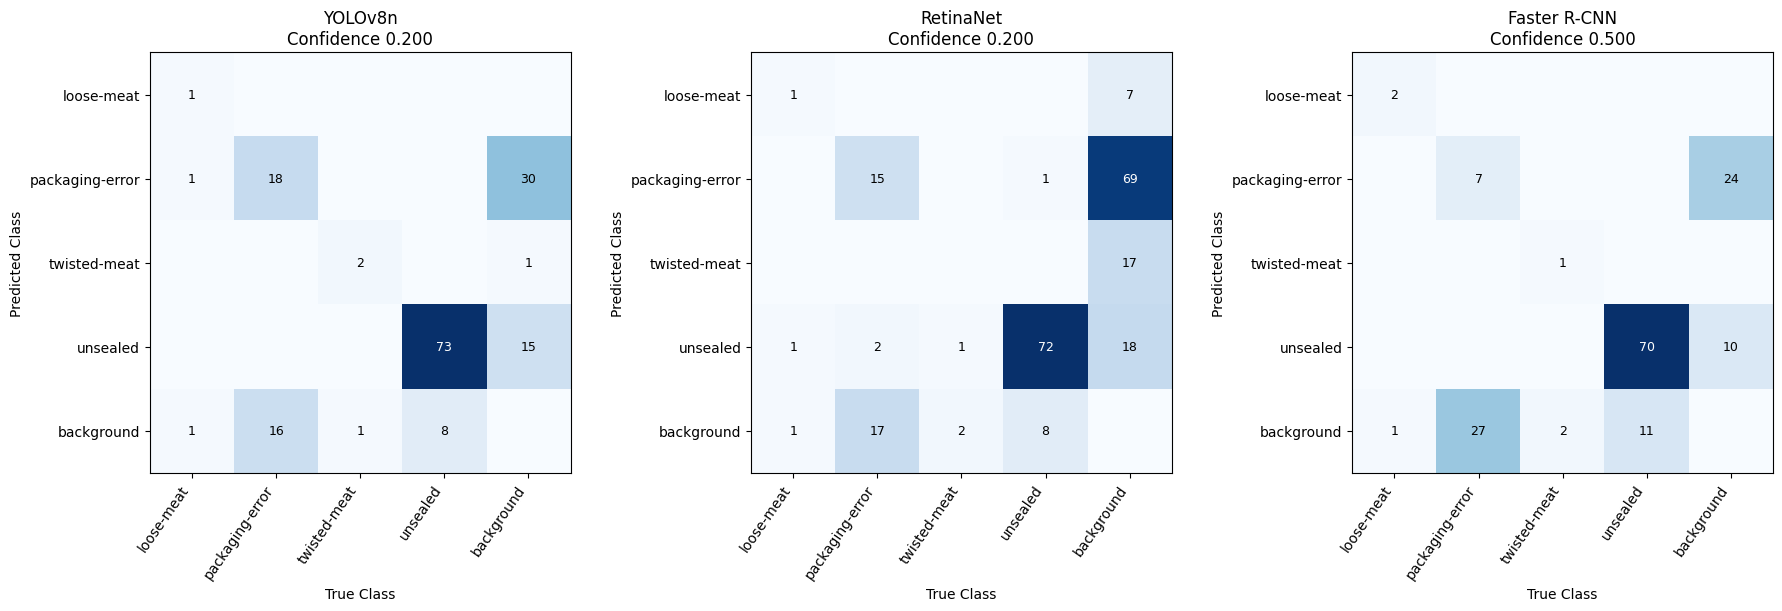

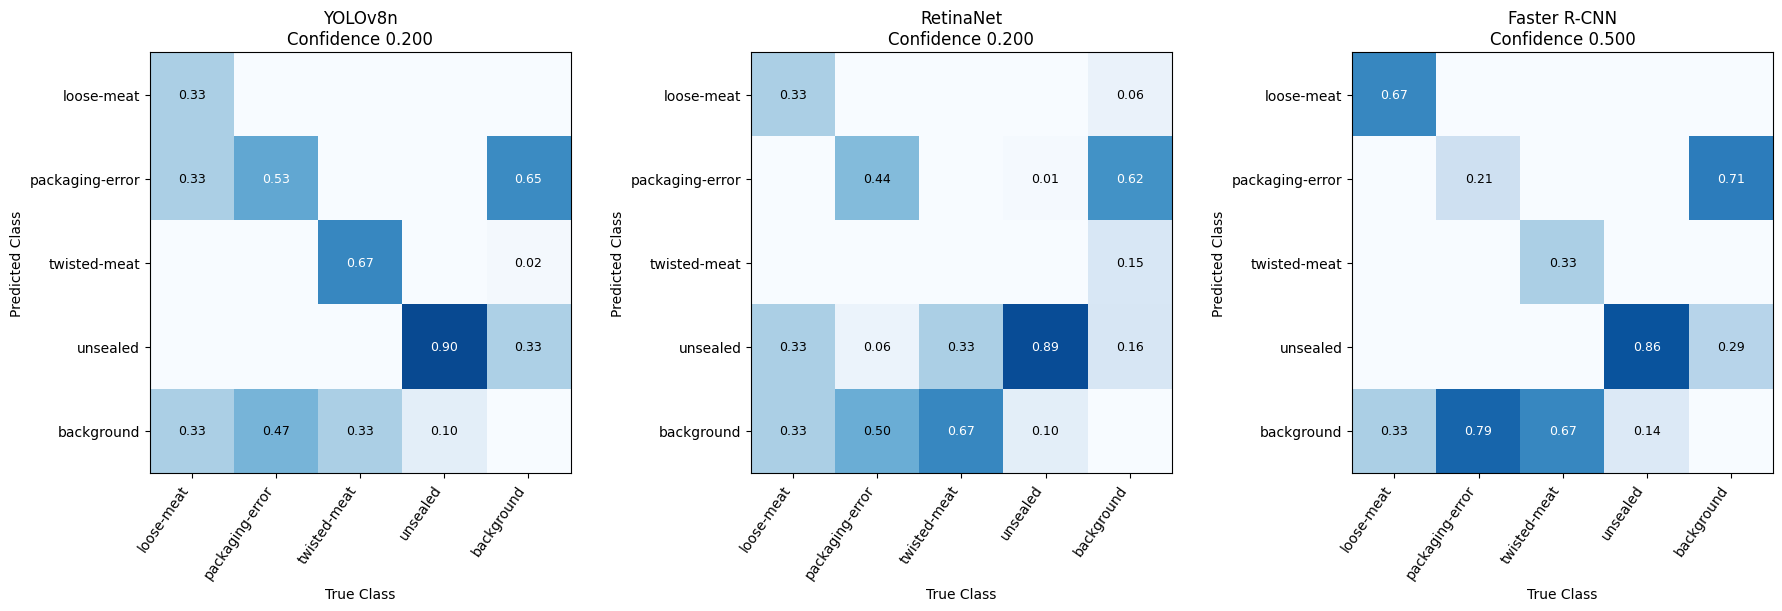

VALIDATION DETECTION ERROR COMPARISON


,Model,Threshold,TP,FP,FN,Missed_to_Background,Unmatched_Predictions,Wrong_Class_Matches
0,YOLOv8n,0.2,94,47,27,26,46,1
1,RetinaNet,0.2,88,116,33,28,111,5
2,Faster R-CNN,0.5,80,34,41,41,34,0


In [12]:

# Compare raw and normalised validation matrices at frozen thresholds.

validation_matrices = {}
error_rows = []

for name in MODEL_NAMES:
    threshold = frozen_thresholds[name]

    overall, class_metrics, matrix = evaluate_threshold(
        predictions=validation_predictions[name],
        targets=valid_targets,
        confidence_threshold=threshold,
        class_names=CLASS_NAMES,
        iou_threshold=MATCH_IOU,
        label_offset=0,
    )

    validation_matrices[name] = matrix

    error_rows.append({
        "Model": name,
        "Threshold": threshold,
        "TP": overall["TP"],
        "FP": overall["FP"],
        "FN": overall["FN"],
        "Missed_to_Background": int(matrix[-1, :-1].sum()),
        "Unmatched_Predictions": int(matrix[:-1, -1].sum()),
        "Wrong_Class_Matches": int(
            matrix[:-1, :-1].sum()
            - np.trace(matrix[:-1, :-1])
        ),
    })

error_df = pd.DataFrame(error_rows)

for normalized in [False, True]:
    fig, axes = plt.subplots(
        1, 3, figsize=(18, 6), constrained_layout=True
    )

    for ax, name in zip(axes, MODEL_NAMES):
        plot_confusion_matrix(
            matrix=validation_matrices[name],
            class_names=CLASS_NAMES,
            title=(
                f"{name}\nConfidence {frozen_thresholds[name]:.3f}"
            ),
            normalized=normalized,
            ax=ax,
        )

    figure_type = "normalized" if normalized else "raw"

    fig.savefig(
        REPORT_DIR / f"validation_confusion_{figure_type}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

print("VALIDATION DETECTION ERROR COMPARISON")
display(error_df.round(4))

error_df.to_csv(
    OUTPUT_DIR / "validation_detection_errors.csv",
    index=False,
)


## 7. Computational Performance

The three saved models are benchmarked using identical Colab hardware and the same validation image.

Each model performs 10 warm-up passes followed by 50 timed inference passes. Disk image loading is excluded from the timing.

Parameter count, raw model-weight storage, median inference latency, FPS and peak allocated GPU memory are compared. The benchmark includes each model's preprocessing and postprocessing, but timing results remain dependent on the Colab environment.

In [13]:

# Benchmark all three models using the original common protocol.

BENCHMARK_REPEATS = 50
WARMUP_REPEATS = 10

benchmark_tensor = load_image_tensor(
    valid_image_paths[0]
).to(device)


def synchronize_gpu():
    """Synchronise CUDA execution before or after an inference pass.

    The function waits for pending GPU operations when CUDA is
    available. No action is performed when running on the CPU.

    Returns:
        None.
    """

    if device.type == "cuda":
        torch.cuda.synchronize()



def weight_size_mb(model):
    """Calculate the raw tensor storage size of a detection model.

    The function sums the storage requirements of all tensors in
    the model state dictionary, including parameters and buffers.
    It does not include optimiser states or checkpoint metadata.

    Args:
        model: Loaded PyTorch or Ultralytics object detection model.

    Returns:
        Model tensor storage size in mebibytes (MiB).
    """

    # Count raw tensor storage rather than full checkpoint file size.
    module = (
        model if isinstance(model, torch.nn.Module)
        else model.model
    )

    return sum(
        tensor.numel() * tensor.element_size()
        for tensor in module.state_dict().values()
    ) / (1024 ** 2)



@torch.inference_mode()
def benchmark_model(name):
    """Benchmark inference latency, throughput and GPU memory usage.

    The selected model performs 10 warm-up inference passes followed
    by 50 timed passes on the same validation image.

    Image-file loading is excluded from the benchmark. CUDA
    synchronisation is applied when a GPU is available.

    Args:
        name: Name of the model to benchmark. Supported values
            are YOLOv8n, RetinaNet and Faster R-CNN.

    Returns:
        Tuple containing:
            - Median inference latency in milliseconds per image.
            - Approximate inference throughput in frames per second.
            - Peak GPU memory allocation in MiB, or NaN on CPU.
    """

    # Exclude image loading from the measured inference time.
    if name == "YOLOv8n":
        image_np = (
            benchmark_tensor.permute(1, 2, 0)
            .mul(255)
            .byte()
            .cpu()
            .numpy()
        )

        def infer():
            """Run one YOLOv8n inference pass for benchmarking.

            Returns:
                Ultralytics detection results for the benchmark image.
            """
            return yolo_model.predict(
                source=image_np,
                imgsz=IMAGE_SIZE,
                conf=0.001,
                iou=0.70,
                max_det=300,
                device=0 if device.type == "cuda" else "cpu",
                verbose=False,
            )

    elif name == "RetinaNet":
        def infer():
            """Run one RetinaNet inference pass for benchmarking.

            Returns:
                Torchvision detection predictions for the benchmark image.
            """
            return retinanet_model([benchmark_tensor])

    else:
        def infer():
            """Run one Faster R-CNN inference pass for benchmarking.

            Returns:
                Torchvision detection predictions for the benchmark image.
            """
            return faster_model([benchmark_tensor])

    for _ in range(WARMUP_REPEATS):
        infer()

    synchronize_gpu()

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    timings = []

    for _ in range(BENCHMARK_REPEATS):
        synchronize_gpu()
        start = time.perf_counter()

        infer()

        synchronize_gpu()
        timings.append(
            (time.perf_counter() - start) * 1000
        )

    median_ms = float(np.median(timings))
    fps = 1000.0 / median_ms

    peak_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if device.type == "cuda"
        else np.nan
    )

    return median_ms, fps, peak_mb


compute_rows = []

for name in MODEL_NAMES:
    print("Benchmarking:", name)

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    median_ms, fps, peak_mb = benchmark_model(name)

    parameters = count_parameters(model_objects[name])

    compute_rows.append({
        "Model": name,
        "Parameters_M": parameters["Total Parameters"] / 1e6,
        "Weight_Size_MB": weight_size_mb(model_objects[name]),
        "Inference_ms": median_ms,
        "FPS": fps,
        "Peak_GPU_MB": peak_mb,
    })

compute_df = pd.DataFrame(compute_rows)

print("\nCOMPUTATIONAL PERFORMANCE")
display(compute_df.round(4))

compute_df.to_csv(
    OUTPUT_DIR / "computational_comparison.csv",
    index=False,
)


Benchmarking: YOLOv8n
Benchmarking: RetinaNet
Benchmarking: Faster R-CNN

COMPUTATIONAL PERFORMANCE


,Model,Parameters_M,Weight_Size_MB,Inference_ms,FPS,Peak_GPU_MB
0,YOLOv8n,3.1387,12.0142,164.5433,6.0774,NaN
1,RetinaNet,36.4149,139.1147,2437.0599,0.4103,NaN
2,Faster R-CNN,43.2715,165.2943,9854.8044,0.1015,NaN


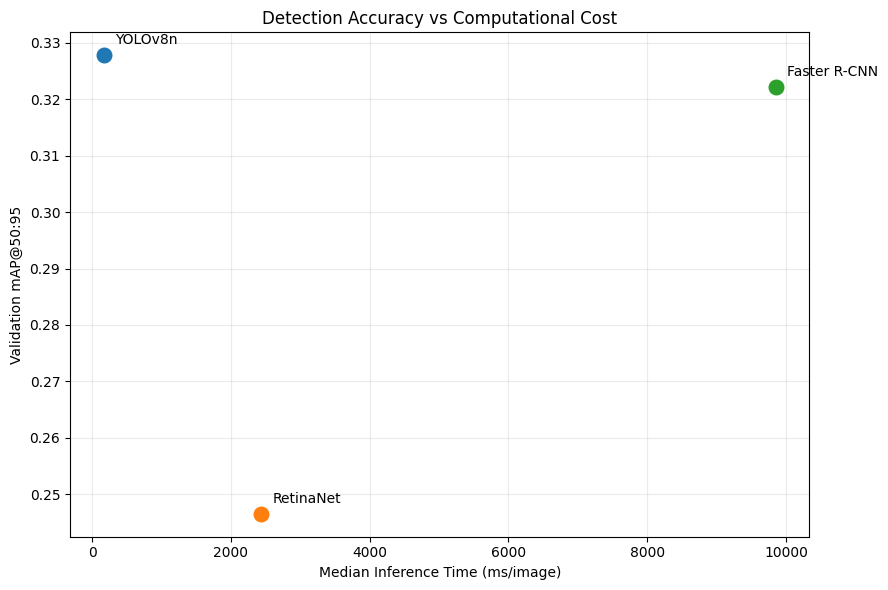

ACCURACY-SPEED COMPARISON


,Model,mAP50,mAP50_95,Parameters_M,Weight_Size_MB,Inference_ms,FPS,Peak_GPU_MB
0,YOLOv8n,0.5147,0.3278,3.1387,12.0142,164.5433,6.0774,NaN
1,RetinaNet,0.4098,0.2465,36.4149,139.1147,2437.0599,0.4103,NaN
2,Faster R-CNN,0.5662,0.3222,43.2715,165.2943,9854.8044,0.1015,NaN


In [14]:

# Compare validation mAP@50:95 against current inference latency.

tradeoff_df = overall_map_df.merge(
    compute_df, on="Model"
)

fig, ax = plt.subplots(figsize=(9, 6))

for _, row in tradeoff_df.iterrows():
    ax.scatter(
        row["Inference_ms"],
        row["mAP50_95"],
        s=110,
    )

    ax.annotate(
        row["Model"],
        (row["Inference_ms"], row["mAP50_95"]),
        xytext=(8, 8),
        textcoords="offset points",
    )

ax.set_xlabel("Median Inference Time (ms/image)")
ax.set_ylabel("Validation mAP@50:95")
ax.set_title("Detection Accuracy vs Computational Cost")
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    REPORT_DIR / "validation_accuracy_vs_latency.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("ACCURACY-SPEED COMPARISON")
display(tradeoff_df.round(4))


## 8. Consolidated Validation Results

The validation comparison combines detection accuracy, confidence-threshold performance, classification errors and computational requirements.

Models are compared using the same dataset and matching criterion. The best model depends on the intended application: overall detection performance, balanced defect recall and computational efficiency may favour different operating points.

The validation-selected model checkpoints and confidence thresholds are frozen before the held-out test evaluation.

In [15]:

# Combine validation detection accuracy, selected thresholds and cost.

final_validation_df = (
    overall_map_df
    .merge(selected_df, on="Model")
    .merge(compute_df, on="Model")
    .merge(
        error_df[
            [
                "Model",
                "Missed_to_Background",
                "Unmatched_Predictions",
                "Wrong_Class_Matches",
            ]
        ],
        on="Model",
    )
)

print("FINAL VALIDATION COMPARISON")
display(final_validation_df.round(4))

final_validation_df.to_csv(
    OUTPUT_DIR / "final_validation_comparison.csv",
    index=False,
)

print("\nVALIDATION FINDINGS")
print(
    "Highest mAP@50:95:",
    final_validation_df.loc[
        final_validation_df["mAP50_95"].idxmax(), "Model"
    ],
)
print(
    "Fastest inference:",
    final_validation_df.loc[
        final_validation_df["Inference_ms"].idxmin(), "Model"
    ],
)
print(
    "Highest Macro-F1:",
    final_validation_df.loc[
        final_validation_df["Best_Macro_F1"].idxmax(), "Model"
    ],
)

# Confirm the validation stage has fixed every test threshold.
assert set(frozen_thresholds) == set(MODEL_NAMES)
assert all(0 <= value <= 1 for value in frozen_thresholds.values())

print("\nValidation-selected thresholds frozen.")


FINAL VALIDATION COMPARISON


,Model,mAP50,mAP50_95,Micro_Threshold,Best_Micro_F1,Macro_Threshold,Best_Macro_F1,Macro_Point_Precision,Macro_Point_Recall,Macro_Point_Micro_F1,Parameters_M,Weight_Size_MB,Inference_ms,FPS,Peak_GPU_MB,Missed_to_Background,Unmatched_Predictions,Wrong_Class_Matches
0,YOLOv8n,0.5147,0.3278,0.45,0.7664,0.2,0.6161,0.6667,0.7769,0.7176,3.1387,12.0142,164.5433,6.0774,NaN,26,46,1
1,RetinaNet,0.4098,0.2465,0.50,0.6979,0.2,0.3142,0.4314,0.7273,0.5415,36.4149,139.1147,2437.0599,0.4103,NaN,28,111,5
2,Faster R-CNN,0.5662,0.3222,0.50,0.6809,0.5,0.5962,0.7018,0.6612,0.6809,43.2715,165.2943,9854.8044,0.1015,NaN,41,34,0



VALIDATION FINDINGS
Highest mAP@50:95: YOLOv8n
Fastest inference: YOLOv8n
Highest Macro-F1: YOLOv8n

Validation-selected thresholds frozen.


## 9. Held-Out Test Evaluation

The final evaluation uses the 80 held-out test images.

All model checkpoints, preprocessing settings, matching procedures and confidence thresholds were selected before accessing test results. The test set is used to measure generalisation, not to optimise the models.

The same common COCO-style evaluator calculates mAP@50 and mAP@50:95. Detection counts are calculated at the previously frozen validation-selected Macro-F1 thresholds.

In [16]:

# Evaluate the held-out test split using frozen validation decisions.

assert len(test_image_paths) == 80
assert set(frozen_thresholds) == set(MODEL_NAMES)

test_predictions = collect_model_predictions(test_image_paths)

test_rows = []
test_class_rows = []
test_matrices = {}

for name in MODEL_NAMES:
    print("Evaluating held-out test:", name)

    predictions = test_predictions[name]

    verify_predictions(predictions, test_targets)

    result = evaluate_map(
        predictions,
        test_targets,
    )

    threshold = frozen_thresholds[name]

    overall, class_metrics, matrix = evaluate_threshold(
        predictions=predictions,
        targets=test_targets,
        confidence_threshold=threshold,
        class_names=CLASS_NAMES,
        iou_threshold=MATCH_IOU,
        label_offset=0,
    )

    test_matrices[name] = matrix

    test_rows.append({
        "Model": name,
        "mAP50": float(result["map_50"]),
        "mAP50_95": float(result["map"]),
        "Threshold": threshold,
        "TP": overall["TP"],
        "FP": overall["FP"],
        "FN": overall["FN"],
        "Precision": overall["Precision"],
        "Recall": overall["Recall"],
        "Micro_F1": overall["F1"],
        "Macro_F1": overall["Macro-F1"],
    })

    ap_by_class = {
        int(class_id): float(ap)
        for class_id, ap in zip(
            result["classes"],
            result["map_per_class"],
        )
    }

    for class_id, class_name in enumerate(CLASS_NAMES):
        test_class_rows.append({
            "Model": name,
            "Class": class_name,
            "AP50_95": ap_by_class.get(class_id, np.nan),
        })

test_results_df = pd.DataFrame(test_rows)
test_class_df = pd.DataFrame(test_class_rows)

print("\nFINAL HELD-OUT TEST RESULTS")
display(test_results_df.round(4))

print("\nTEST PER-CLASS AP@50:95")
display(
    test_class_df.pivot(
        index="Class",
        columns="Model",
        values="AP50_95",
    ).round(4)
)

test_results_df.to_csv(
    OUTPUT_DIR / "final_test_results.csv",
    index=False,
)

test_class_df.to_csv(
    OUTPUT_DIR / "final_test_per_class_ap.csv",
    index=False,
)


Evaluating held-out test: YOLOv8n
Evaluating held-out test: RetinaNet
Evaluating held-out test: Faster R-CNN

FINAL HELD-OUT TEST RESULTS


,Model,mAP50,mAP50_95,Threshold,TP,FP,FN,Precision,Recall,Micro_F1,Macro_F1
0,YOLOv8n,0.5252,0.2698,0.2,54,24,25,0.6923,0.6835,0.6879,0.3321
1,RetinaNet,0.2797,0.1494,0.2,52,70,27,0.4262,0.6582,0.5174,0.2704
2,Faster R-CNN,0.2716,0.1482,0.5,48,18,31,0.7273,0.6076,0.6621,0.2890



TEST PER-CLASS AP@50:95


Model,Faster R-CNN,RetinaNet,YOLOv8n
Class,,,
loose-meat,0.0004,0.0000,0.2608
packaging-error,0.0619,0.0711,0.1481
twisted-meat,0.0027,0.0000,0.0921
unsealed,0.5280,0.5266,0.5782


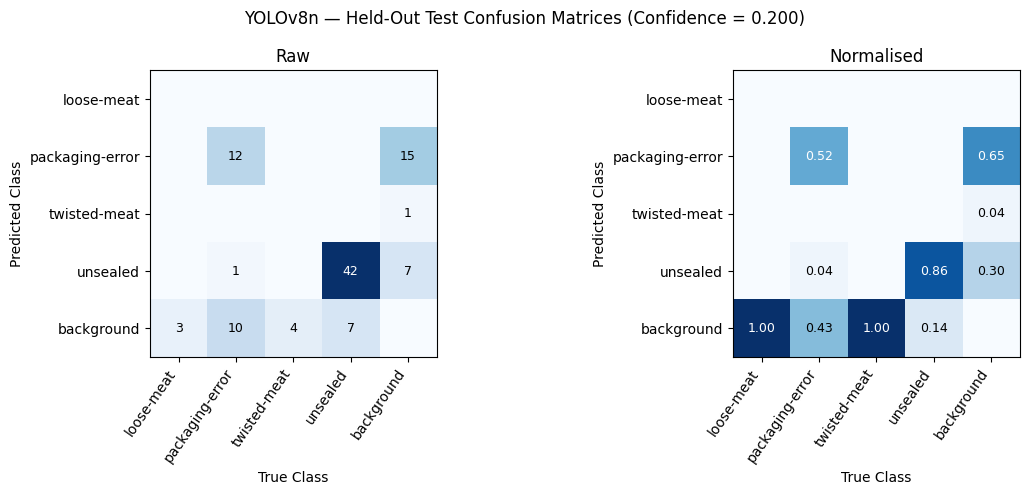

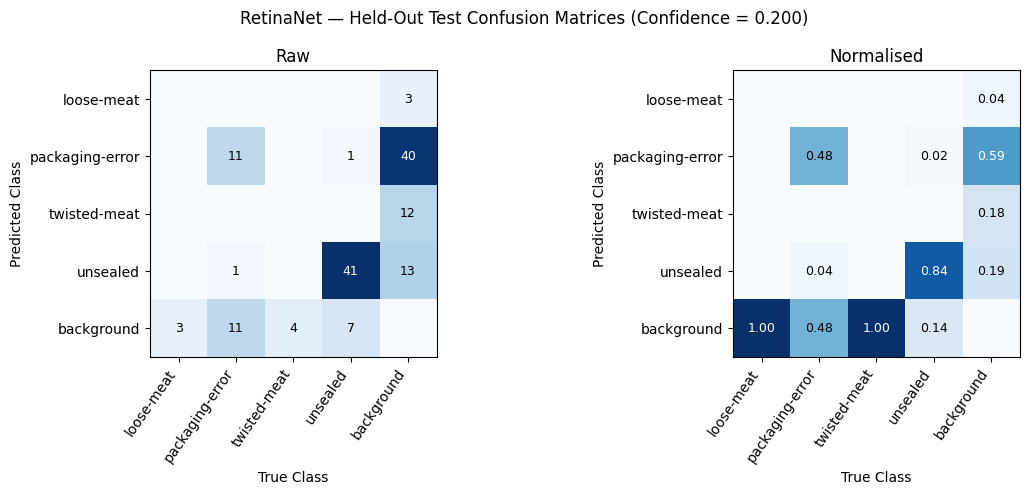

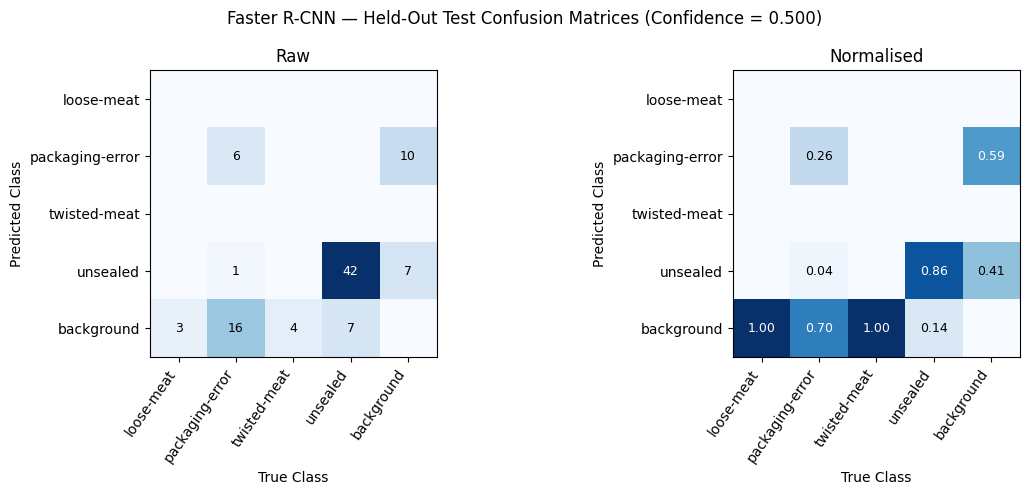

In [17]:

# Display raw and normalised test confusion matrices for each model.

for name in MODEL_NAMES:
    matrix = test_matrices[name]

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5)
    )

    plot_confusion_matrix(
        matrix,
        class_names=CLASS_NAMES,
        title="Raw",
        normalized=False,
        ax=axes[0],
    )

    plot_confusion_matrix(
        matrix,
        class_names=CLASS_NAMES,
        title="Normalised",
        normalized=True,
        ax=axes[1],
    )

    fig.suptitle(
        f"{name} — Held-Out Test Confusion Matrices "
        f"(Confidence = {frozen_thresholds[name]:.3f})"
    )

    fig.tight_layout()

    fig.savefig(
        REPORT_DIR
        / f"{name.replace(' ', '_')}_test_confusion.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)


VALIDATION VS TEST PERFORMANCE


,Model,mAP50_Valid,mAP50_95_Valid,mAP50_Test,mAP50_95_Test,mAP50_95_Change
0,YOLOv8n,0.5147,0.3278,0.5252,0.2698,-0.0580
1,RetinaNet,0.4098,0.2465,0.2797,0.1494,-0.0971
2,Faster R-CNN,0.5662,0.3222,0.2716,0.1482,-0.1740


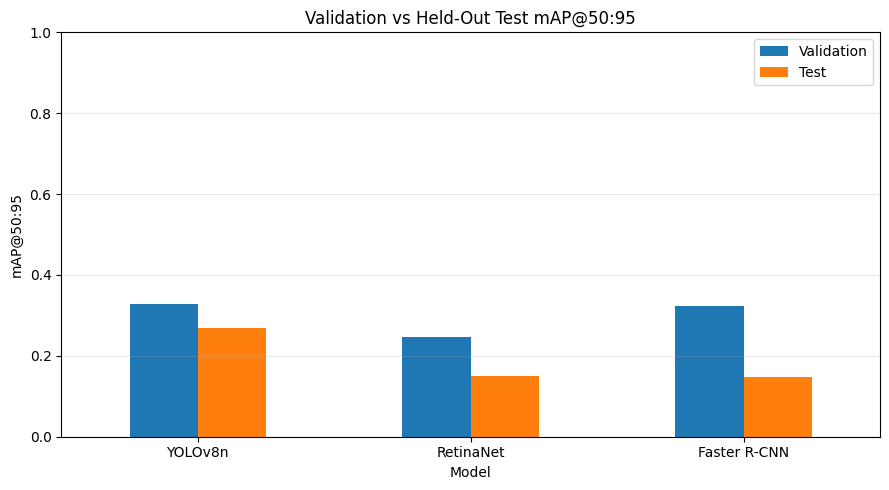

In [18]:

# Compare common-evaluator validation and test average precision.

comparison_df = overall_map_df.merge(
    test_results_df[
        ["Model", "mAP50", "mAP50_95"]
    ],
    on="Model",
    suffixes=("_Valid", "_Test"),
)

comparison_df["mAP50_95_Change"] = (
    comparison_df["mAP50_95_Test"]
    - comparison_df["mAP50_95_Valid"]
)

print("VALIDATION VS TEST PERFORMANCE")
display(comparison_df.round(4))

ax = comparison_df.set_index("Model")[
    ["mAP50_95_Valid", "mAP50_95_Test"]
].plot(
    kind="bar",
    figsize=(9, 5),
)

ax.set_title("Validation vs Held-Out Test mAP@50:95")
ax.set_ylabel("mAP@50:95")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(["Validation", "Test"])
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "validation_vs_test_map.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

comparison_df.to_csv(
    OUTPUT_DIR / "validation_vs_test_comparison.csv",
    index=False,
)


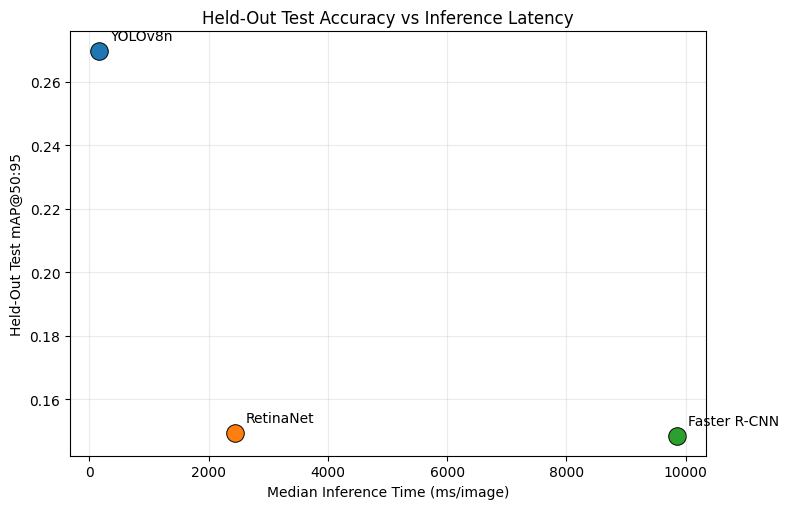

TEST ACCURACY AND COMPUTATIONAL COST


,Model,mAP50_95,Parameters_M,Weight_Size_MB,Inference_ms,FPS,Peak_GPU_MB
0,YOLOv8n,0.2698,3.1387,12.0142,164.5433,6.0774,NaN
1,RetinaNet,0.1494,36.4149,139.1147,2437.0599,0.4103,NaN
2,Faster R-CNN,0.1482,43.2715,165.2943,9854.8044,0.1015,NaN


In [19]:

# Generate Figure 5.2.0 from actual test and benchmark results.

test_tradeoff_df = test_results_df[
    ["Model", "mAP50_95"]
].merge(
    compute_df,
    on="Model",
)

fig, ax = plt.subplots(figsize=(8, 5.2))

for _, row in test_tradeoff_df.iterrows():
    ax.scatter(
        row["Inference_ms"],
        row["mAP50_95"],
        s=160,
        edgecolor="black",
        linewidth=0.7,
    )

    ax.annotate(
        row["Model"],
        (row["Inference_ms"], row["mAP50_95"]),
        xytext=(8, 8),
        textcoords="offset points",
    )

ax.set_xlabel("Median Inference Time (ms/image)")
ax.set_ylabel("Held-Out Test mAP@50:95")
ax.set_title("Held-Out Test Accuracy vs Inference Latency")
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    REPORT_DIR / "figure_5_2_0_accuracy_vs_latency.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    REPORT_DIR / "figure_5_2_0_accuracy_vs_latency.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("TEST ACCURACY AND COMPUTATIONAL COST")
display(test_tradeoff_df.round(4))


## 10. Faster R-CNN Generalisation Diagnostics

The Faster R-CNN model showed a substantial reduction in detection performance between validation and test data.

To investigate this result without modifying the selected checkpoint or confidence threshold, three additional diagnostics are performed:

1. Ground-truth and prediction counts by defect class.
2. Prediction confidence distributions on the held-out test set.
3. Best prediction-to-ground-truth IoU for each defect category.

These analyses are descriptive only. No test-derived threshold adjustment is performed.

In [20]:

# Compare Faster R-CNN validation and test detection counts.

name = "Faster R-CNN"
threshold = frozen_thresholds[name]

def count_predictions_by_class(predictions, threshold):
    """Count accepted detections for each defect class.

    Predictions are filtered using the specified confidence
    threshold before their class labels are counted.

    Args:
        predictions: List of detection dictionaries containing
            predicted confidence scores and zero-based class labels.
        threshold: Minimum confidence required to accept a prediction.

    Returns:
        NumPy array containing the number of accepted predictions
        for each of the four defect classes.
    """

    counts = np.zeros(NUM_CLASSES, dtype=int)

    for record in predictions:
        keep = record["scores"] >= threshold

        for label in record["labels"][keep]:
            counts[int(label)] += 1

    return counts


valid_matrix = validation_matrices[name]
test_matrix = test_matrices[name]

valid_gt_counts = count_annotations(valid_targets)
test_gt_counts = count_annotations(test_targets)

diagnostic_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Validation_GT": valid_gt_counts,
    "Test_GT": test_gt_counts,
    "Validation_Predictions": count_predictions_by_class(
        validation_predictions[name], threshold
    ),
    "Test_Predictions": count_predictions_by_class(
        test_predictions[name], threshold
    ),
    "Validation_TP": np.diag(valid_matrix)[:NUM_CLASSES],
    "Test_TP": np.diag(test_matrix)[:NUM_CLASSES],
})

diagnostic_df["Validation_Recall"] = (
    diagnostic_df["Validation_TP"]
    / diagnostic_df["Validation_GT"].replace(0, np.nan)
)

diagnostic_df["Test_Recall"] = (
    diagnostic_df["Test_TP"]
    / diagnostic_df["Test_GT"].replace(0, np.nan)
)

print("FASTER R-CNN GENERALISATION DIAGNOSTICS")
print("Frozen threshold:", threshold)

display(diagnostic_df.round(4))

diagnostic_df.to_csv(
    OUTPUT_DIR / "faster_rcnn_generalisation.csv",
    index=False,
)


FASTER R-CNN GENERALISATION DIAGNOSTICS
Frozen threshold: 0.5


,Class,Validation_GT,Test_GT,Validation_Predictions,Test_Predictions,Validation_TP,Test_TP,Validation_Recall,Test_Recall
0,loose-meat,3,3,2,0,2,0,0.6667,0.0000
1,packaging-error,34,23,31,16,7,6,0.2059,0.2609
2,twisted-meat,3,4,1,0,1,0,0.3333,0.0000
3,unsealed,81,49,80,50,70,42,0.8642,0.8571


In [21]:

# Inspect Faster R-CNN test confidence scores without changing thresholds.

confidence_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):
    scores = []

    for prediction in test_predictions["Faster R-CNN"]:
        mask = prediction["labels"] == class_id
        scores.extend(
            prediction["scores"][mask].tolist()
        )

    confidence_rows.append({
        "Class": class_name,
        "Prediction_Count": len(scores),
        "Mean_Confidence": (
            float(np.mean(scores)) if scores else np.nan
        ),
        "Median_Confidence": (
            float(np.median(scores)) if scores else np.nan
        ),
        "Maximum_Confidence": (
            float(np.max(scores)) if scores else np.nan
        ),
        "Above_Frozen_Threshold": sum(
            score >= frozen_thresholds["Faster R-CNN"]
            for score in scores
        ),
    })

confidence_df = pd.DataFrame(confidence_rows)

print("FASTER R-CNN TEST PREDICTION CONFIDENCE")
display(confidence_df.round(4))

confidence_df.to_csv(
    OUTPUT_DIR / "faster_rcnn_test_confidence.csv",
    index=False,
)


FASTER R-CNN TEST PREDICTION CONFIDENCE


,Class,Prediction_Count,Mean_Confidence,Median_Confidence,Maximum_Confidence,Above_Frozen_Threshold
0,loose-meat,212,0.0082,0.0044,0.1228,0
1,packaging-error,292,0.0660,0.0042,0.9717,16
2,twisted-meat,208,0.0093,0.0043,0.1958,0
3,unsealed,192,0.2777,0.0113,0.9962,50


In [22]:

# Compare each test ground truth with same-class predicted boxes.

localisation_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):
    best_ious = []
    best_scores = []

    for prediction, target in zip(
        test_predictions["Faster R-CNN"],
        test_targets,
    ):
        gt_mask = target["labels"] == class_id
        pred_mask = prediction["labels"] == class_id

        gt_boxes = target["boxes"][gt_mask]
        pred_boxes = prediction["boxes"][pred_mask]
        pred_scores = prediction["scores"][pred_mask]

        for gt_box in gt_boxes:
            if len(pred_boxes) == 0:
                best_ious.append(0.0)
                best_scores.append(0.0)
                continue

            ious = box_iou(
                gt_box.unsqueeze(0),
                pred_boxes,
            )[0]

            best_index = int(ious.argmax())

            best_ious.append(float(ious[best_index]))
            best_scores.append(float(pred_scores[best_index]))

    localisation_rows.append({
        "Class": class_name,
        "GT_Count": len(best_ious),
        "Mean_Best_IoU": (
            float(np.mean(best_ious))
            if best_ious else np.nan
        ),
        "GT_with_IoU_50": sum(
            value >= 0.50 for value in best_ious
        ),
        "Mean_Best_Score": (
            float(np.mean(best_scores))
            if best_scores else np.nan
        ),
    })

localisation_df = pd.DataFrame(localisation_rows)

print("FASTER R-CNN TEST LOCALISATION DIAGNOSTICS")
display(localisation_df.round(4))

localisation_df.to_csv(
    OUTPUT_DIR / "faster_rcnn_test_localisation.csv",
    index=False,
)


FASTER R-CNN TEST LOCALISATION DIAGNOSTICS


,Class,GT_Count,Mean_Best_IoU,GT_with_IoU_50,Mean_Best_Score
0,loose-meat,3,0.3283,1,0.0139
1,packaging-error,23,0.5135,16,0.1649
2,twisted-meat,4,0.3754,2,0.0085
3,unsealed,49,0.7835,46,0.7769


## 11. Final Findings and Limitations

### Detection Accuracy

The common-evaluator validation comparison assesses the performance of YOLOv8n, RetinaNet and Faster R-CNN on identical images and annotations.

The held-out test evaluation provides additional evidence of generalisation to previously unseen examples. Differences between validation and test performance must be interpreted alongside the number and distribution of defects in each split.

### Confidence Thresholds

The final test results use confidence thresholds selected exclusively from validation data. The selected thresholds remain fixed during test evaluation.

Micro-F1 and Macro-F1 are both reported because overall performance may conceal poor detection of less frequent defect categories.

### Computational Cost

YOLOv8n has considerably fewer parameters than RetinaNet and Faster R-CNN. The latency comparison considers the practical trade-off between detection performance and computational efficiency.

### Limitations

- The dataset is class-imbalanced, particularly for loose-meat and twisted-meat.
- The test dataset is relatively small, so class-specific AP values are sensitive to individual detections.
- Annotation quality has not been independently verified.
- Confidence thresholds and inference postprocessing can affect reported detection counts.
- Inference latency and GPU memory measurements depend on Colab hardware and software versions.
- The checkpoint-selection training curves and the common-evaluator comparison use different evaluation protocols and should not be interpreted as interchangeable results.

No new training is performed. The models are evaluated using their original saved checkpoints.

In [23]:

# Check final results against the original executed Notebook 07.

reference_validation_map = {
    "YOLOv8n": 0.3278,
    "RetinaNet": 0.2465,
    "Faster R-CNN": 0.3222,
}

reference_test_map = {
    "YOLOv8n": 0.2698,
    "RetinaNet": 0.1494,
    "Faster R-CNN": 0.1482,
}

reference_test_counts = {
    "YOLOv8n": (54, 24, 25),
    "RetinaNet": (52, 70, 27),
    "Faster R-CNN": (48, 18, 31),
}

print("FINAL MODEL-COMPARISON REPRODUCIBILITY")

all_checks_pass = True

for name in MODEL_NAMES:
    valid_row = overall_map_df.loc[
        overall_map_df["Model"] == name
    ].iloc[0]

    test_row = test_results_df.loc[
        test_results_df["Model"] == name
    ].iloc[0]

    observed_valid = float(valid_row["mAP50_95"])
    observed_test = float(test_row["mAP50_95"])

    validation_match = (
        abs(observed_valid - reference_validation_map[name]) <= 0.005
    )
    test_match = (
        abs(observed_test - reference_test_map[name]) <= 0.005
    )

    observed_counts = (
        int(test_row["TP"]),
        int(test_row["FP"]),
        int(test_row["FN"]),
    )

    count_match = (
        observed_counts == reference_test_counts[name]
    )

    all_checks_pass = all_checks_pass and all([
        validation_match,
        test_match,
        count_match,
    ])

    print(f"\n{name}")
    print(
        f"Validation mAP@50:95: {observed_valid:.4f}",
        "match:", validation_match,
    )
    print(
        f"Test mAP@50:95: {observed_test:.4f}",
        "match:", test_match,
    )
    print(
        f"Test TP/FP/FN: {observed_counts}",
        "reference:", reference_test_counts[name],
        "match:", count_match,
    )
    print(
        "Frozen test threshold:",
        frozen_thresholds[name],
    )

print("\nFINAL REPRODUCIBILITY STATUS")

if all_checks_pass:
    print("PASS")
else:
    print(
        "REVIEW REQUIRED"
    )

print("\nNo dataset generation or model training was performed.")
print("Original checkpoints were not modified.")
print("Saved comparison outputs:", OUTPUT_DIR)


FINAL MODEL-COMPARISON REPRODUCIBILITY

YOLOv8n
Validation mAP@50:95: 0.3278 match: True
Test mAP@50:95: 0.2698 match: True
Test TP/FP/FN: (54, 24, 25) reference: (54, 24, 25) match: True
Frozen test threshold: 0.2

RetinaNet
Validation mAP@50:95: 0.2465 match: True
Test mAP@50:95: 0.1494 match: True
Test TP/FP/FN: (52, 70, 27) reference: (52, 70, 27) match: True
Frozen test threshold: 0.2

Faster R-CNN
Validation mAP@50:95: 0.3222 match: True
Test mAP@50:95: 0.1482 match: True
Test TP/FP/FN: (48, 18, 31) reference: (48, 18, 31) match: True
Frozen test threshold: 0.5

FINAL REPRODUCIBILITY STATUS
PASS

No dataset generation or model training was performed.
Original checkpoints were not modified.
Saved comparison outputs: /content/gdrive_new/MyDrive/MMA3001_Project/comparison_results
